# Numerical Solution of the Blasius Boundary-Value Problem

**Submitted by:** S. Vignesh  
**Student ID:** SC26M019

## Introduction

In this assignment, I solve the Blasius equation for the laminar boundary layer over a flat plate. The equation is a boundary-value problem because the conditions are specified at the wall and far away from the wall. I use the shooting method to convert it into an initial-value problem.

The resulting equations are integrated using two methods: third-order Runge–Kutta (RK3) and classical fourth-order Runge–Kutta (RK4). For each method, I use bisection to find the missing wall condition $f''(0)$. I then compare the results for the step sizes given in the assignment.

## 1. Governing equation and boundary conditions

For steady, incompressible flow over a flat plate, the similarity transformation is

$$
\eta=y\sqrt{\frac{U_\infty}{\nu x}},\qquad
\frac{u}{U_\infty}=f'(\eta).
$$

Using this transformation, the boundary-layer equations reduce to the Blasius equation:

$$
\boxed{f'''+\frac12ff''=0,\qquad 0<\eta<\infty.}
$$

The boundary conditions are

$$
f(0)=0,\qquad f'(0)=0,\qquad
f'(\eta)\rightarrow1\quad\text{as}\quad\eta\rightarrow\infty.
$$

At the plate, $f(0)=0$ represents zero wall-normal flow and $f'(0)=0$ represents the no-slip condition. Far from the plate, the flow approaches the free-stream velocity, so $f'(\eta)$ approaches one.

A computer cannot integrate to infinity. I therefore use $\eta_\infty=10$ as the finite end of the computational domain.

## 2. Writing the equation as a first-order system

The Blasius equation is third order, so I introduce three variables:

$$
u_1=f,\qquad u_2=f',\qquad u_3=f''.
$$

Differentiating these definitions gives

$$
u_1'=u_2,\qquad u_2'=u_3.
$$

The original equation gives the last equation:

$$
f'''=-\frac12ff''
\quad\Rightarrow\quad
u_3'=-\frac12u_1u_3.
$$

The system I use in the program is therefore

$$
\boxed{
u_1'=u_2,\qquad
u_2'=u_3,\qquad
u_3'=-\frac12u_1u_3.
}
$$

At the wall, the first two initial values are known. The third one is not known, so I write it as

$$
u_1(0)=0,\qquad u_2(0)=0,\qquad u_3(0)=s,
$$

where

$$
\boxed{s=f''(0)}
$$

is the shooting parameter that has to be found.

## 3. Python setup

I first import NumPy for the numerical calculations and Matplotlib for the plots. The function `first_order` returns the three derivatives at a given state. Both Runge–Kutta methods use this same function.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

eta_inf = 10
h_values = [0.4, 0.2, 0.1, 0.05, 0.025]

def first_order(u1, u2, u3):
    du1 = u2
    du2 = u3
    du3 = -u1 * u3 / 2
    return np.array([du1, du2, du3])


## 4. RK3 integration

For the first calculation, I use the third-order Runge–Kutta formula. At each step, three intermediate slopes are evaluated:

$$
\begin{aligned}
K_1 &= hG(Y_n),\\
K_2 &= hG\left(Y_n+\frac{K_1}{2}\right),\\
K_3 &= hG(Y_n-K_1+2K_2).
\end{aligned}
$$

The solution is then advanced using

$$
Y_{n+1}=Y_n+\frac{K_1+4K_2+K_3}{6}.
$$

The function `RK3` applies this formula from $\eta=0$ to $\eta=\eta_\infty$. It returns the coordinate array, the three solution variables, and the residual in the far-field condition.

In [2]:
def RK3(s, h, eta_inf):
    N = round(eta_inf / h)
    h = eta_inf / N
    eta = np.linspace(0, eta_inf, N + 1)
    Y = np.zeros((N + 1, 3))
    Y[0] = [0, 0, s]

    for i in range(N):
        K1 = h * first_order(Y[i, 0], Y[i, 1], Y[i, 2])
        K2 = h * first_order(
            Y[i, 0] + K1[0]/2,
            Y[i, 1] + K1[1]/2,
            Y[i, 2] + K1[2]/2
        )
        K3 = h * first_order(
            Y[i, 0] - K1[0] + 2*K2[0],
            Y[i, 1] - K1[1] + 2*K2[1],
            Y[i, 2] - K1[2] + 2*K2[2]
        )
        Y[i+1] = Y[i] + (K1 + 4*K2 + K3)/6

    return eta, Y, Y[-1, 1] - 1


## 5. Finding the shooting parameter with RK3

For a trial value of $s$, I integrate the equations and check the velocity at the end of the domain. The residual is

$$
F(s)=f'(\eta_\infty;s)-1.
$$

The correct value of $s$ should make this residual zero. I use bisection because it is a straightforward root-finding method: I start with two trial values that give residuals of opposite signs, calculate the midpoint, and keep the half-interval that still contains the sign change. This process continues until the interval is smaller than the chosen tolerance.

The code below applies this procedure to the RK3 solution.

In [3]:
def residual_RK3(s, h):
    eta, Y, err = RK3(s, h, eta_inf)
    return err

def bisection_RK3(sl, su, eps, h):
    fl = residual_RK3(sl, h)
    fu = residual_RK3(su, h)

    if fl * fu > 0:
        raise ValueError("Initial interval does not bracket a root.")

    while (su - sl)/2 > eps:
        sm = (sl + su)/2
        fm = residual_RK3(sm, h)

        if fl * fm < 0:
            su = sm
            fu = fm
        else:
            sl = sm
            fl = fm

    return (sl + su)/2

eps = 1e-13
h = 0.1
s_RK3 = bisection_RK3(0.2, 0.5, eps, h)
eta_RK3, Y_RK3, err_RK3 = RK3(s_RK3, h, eta_inf)

print("RK3 shooting parameter f''(0) =", s_RK3)
print("f'(eta_inf) =", Y_RK3[-1, 1])
print("Residual =", err_RK3)


RK3 shooting parameter f''(0) = 0.3320565334008507
f'(eta_inf) = 0.9999999999998738
Residual = -1.262323578998803e-13


## 6. RK3 solution profiles

After finding $s$, I integrate the system once more using that value and plot $f$, $f'$, and $f''$ against $\eta$.

The plots are useful for checking the boundary conditions visually. At the wall, $f'(0)$ should be zero. As $\eta$ increases, $f'(\eta)$ should approach one, while $f''(\eta)$ should decrease towards zero.

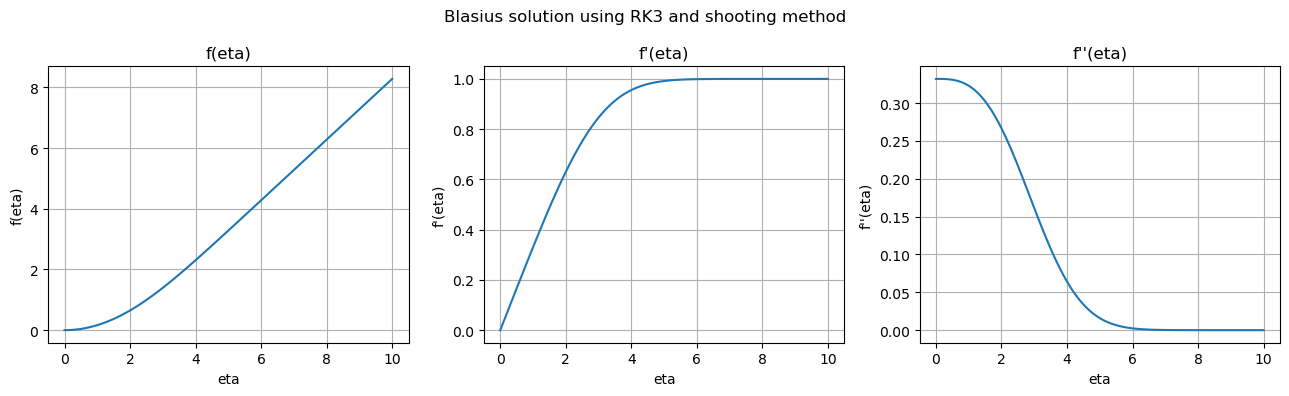

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].plot(eta_RK3, Y_RK3[:, 0])
ax[0].set_xlabel("eta")
ax[0].set_ylabel("f(eta)")
ax[0].set_title("f(eta)")

ax[1].plot(eta_RK3, Y_RK3[:, 1])
ax[1].set_xlabel("eta")
ax[1].set_ylabel("f'(eta)")
ax[1].set_title("f'(eta)")

ax[2].plot(eta_RK3, Y_RK3[:, 2])
ax[2].set_xlabel("eta")
ax[2].set_ylabel("f''(eta)")
ax[2].set_title("f''(eta)")

for a in ax:
    a.grid(True)

plt.suptitle("Blasius solution using RK3 and shooting method")
plt.tight_layout()
plt.show()


## 7. RK3 step-size study

The assignment asks for the calculation to be repeated with

$$
h=0.4,\;0.2,\;0.1,\;0.05,\;0.025.
$$

For every step size, I run the shooting method again and record the resulting value of $s$. I compare it with the reference value

$$
s_{\mathrm{ref}}=0.3320573362
$$

using the absolute error

$$
E(h)=|s_{\mathrm{numerical}}-s_{\mathrm{ref}}|.
$$

To estimate the observed order between two successive step sizes, I use

$$
p=\frac{\log(E_i/E_{i+1})}{\log(h_i/h_{i+1})}.
$$

Since the integration formula is third order, the observed order should approach three as the calculation enters the asymptotic range.

In [5]:
s_reference = 0.3320573362
s_RK3_values = []
error_RK3_values = []

for hi in h_values:
    si = bisection_RK3(0.2, 0.5, eps, hi)
    s_RK3_values.append(si)
    error_RK3_values.append(abs(si - s_reference))

print("RK3 convergence results")
print("h           shooting parameter       absolute error")
for hi, si, ei in zip(h_values, s_RK3_values, error_RK3_values):
    print(f"{hi:<10} {si:.12f}          {ei:.6e}")

order_RK3 = []
for i in range(len(h_values) - 1):
    p = np.log(error_RK3_values[i] / error_RK3_values[i+1]) / np.log(h_values[i] / h_values[i+1])
    order_RK3.append(p)

print("Observed RK3 orders:", order_RK3)


RK3 convergence results
h           shooting parameter       absolute error
0.4        0.331977144770          8.019143e-05
0.2        0.332049598249          7.737951e-06
0.1        0.332056533401          8.027991e-07
0.05       0.332057247592          8.860807e-08
0.025      0.332057326701          9.498944e-09
Observed RK3 orders: [np.float64(3.3734244767717954), np.float64(3.268840684725567), np.float64(3.179529140474386), np.float64(3.221598988175896)]


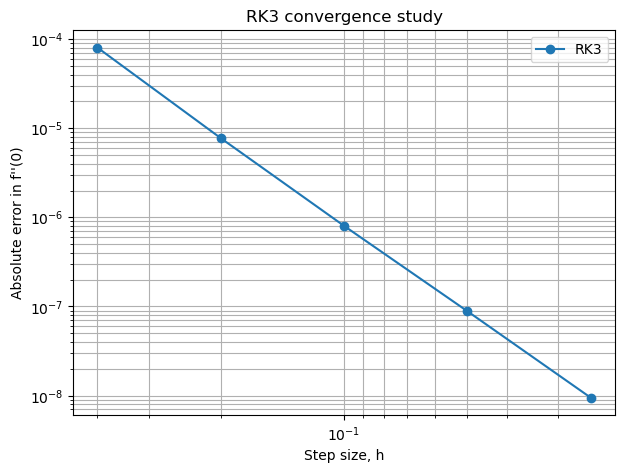

In [6]:
plt.figure(figsize=(7, 5))
plt.loglog(h_values, error_RK3_values, "o-", label="RK3")
plt.xlabel("Step size, h")
plt.ylabel("Absolute error in f''(0)")
plt.title("RK3 convergence study")
plt.grid(True, which="both")
plt.legend()
plt.gca().invert_xaxis()
plt.show()


### Comment on the RK3 results

I use the table and log–log plot above to see how the shooting-parameter error changes as the step size is reduced. A smaller error for a smaller step size indicates that the numerical solution is converging. The order values provide a more direct check of the method: for RK3, the expected order is three. The values printed by the notebook should be used when writing the final observation, rather than assuming that every calculated order will be exactly three.

## 8. Classical RK4 method

I now repeat the integration using the classical fourth-order Runge–Kutta method. It uses four intermediate slopes:

$$
\begin{aligned}
K_1 &= hG(Y_n),\\
K_2 &= hG\left(Y_n+\frac{K_1}{2}\right),\\
K_3 &= hG\left(Y_n+\frac{K_2}{2}\right),\\
K_4 &= hG(Y_n+K_3).
\end{aligned}
$$

The update formula is

$$
Y_{n+1}=Y_n+\frac{K_1+2K_2+2K_3+K_4}{6}.
$$

The differential equations and initial conditions have not changed. Only the numerical integration formula is different. This makes it possible to compare RK3 and RK4 on the same problem.

In [7]:
def RK4(s, h, eta_inf):
    N = round(eta_inf / h)
    h = eta_inf / N
    eta = np.linspace(0, eta_inf, N + 1)
    Y = np.zeros((N + 1, 3))
    Y[0] = [0, 0, s]

    for i in range(N):
        K1 = h * first_order(Y[i, 0], Y[i, 1], Y[i, 2])
        K2 = h * first_order(
            Y[i, 0] + K1[0]/2,
            Y[i, 1] + K1[1]/2,
            Y[i, 2] + K1[2]/2
        )
        K3 = h * first_order(
            Y[i, 0] + K2[0]/2,
            Y[i, 1] + K2[1]/2,
            Y[i, 2] + K2[2]/2
        )
        K4 = h * first_order(
            Y[i, 0] + K3[0],
            Y[i, 1] + K3[1],
            Y[i, 2] + K3[2]
        )
        Y[i+1] = Y[i] + (K1 + 2*K2 + 2*K3 + K4)/6

    return eta, Y, Y[-1, 1] - 1


## 9. Finding the shooting parameter with RK4

I use the same residual,

$$
F(s)=f'(\eta_\infty;s)-1,
$$

but evaluate it using the RK4 integration function. The bisection procedure is otherwise unchanged. I have given the RK4 residual and bisection functions separate names so that the RK3 and RK4 calculations can be kept distinct in the notebook.

After bisection gives the value of $s$, I run RK4 once more with that value and print the solution at the end of the domain.

In [8]:
def residual_RK4(s, h):
    eta, Y, err = RK4(s, h, eta_inf)
    return err

def bisection_RK4(sl, su, eps, h):
    fl = residual_RK4(sl, h)
    fu = residual_RK4(su, h)

    if fl * fu > 0:
        raise ValueError("Initial interval does not bracket a root.")

    while (su - sl)/2 > eps:
        sm = (sl + su)/2
        fm = residual_RK4(sm, h)

        if fl * fm < 0:
            su = sm
            fu = fm
        else:
            sl = sm
            fl = fm

    return (sl + su)/2

s_RK4 = bisection_RK4(0.2, 0.5, eps, h)
eta_RK4, Y_RK4, err_RK4 = RK4(s_RK4, h, eta_inf)

print("RK4 shooting parameter f''(0) =", s_RK4)
print("f'(eta_inf) =", Y_RK4[-1, 1])
print("Residual =", err_RK4)


RK4 shooting parameter f''(0) = 0.3320573456105422
f'(eta_inf) = 0.9999999999999905
Residual = -9.547918011776346e-15


## 10. RK4 solution profiles

The following plots show the RK4 solution for $f$, $f'$, and $f''$. I check them against the same physical behaviour considered for RK3: the velocity starts from zero at the wall and approaches the free-stream value, while the second derivative decreases away from the plate.

The two sets of profiles should have the same overall shape. Differences between the methods are expected to be more noticeable in the numerical errors than in the general shape of the curves.

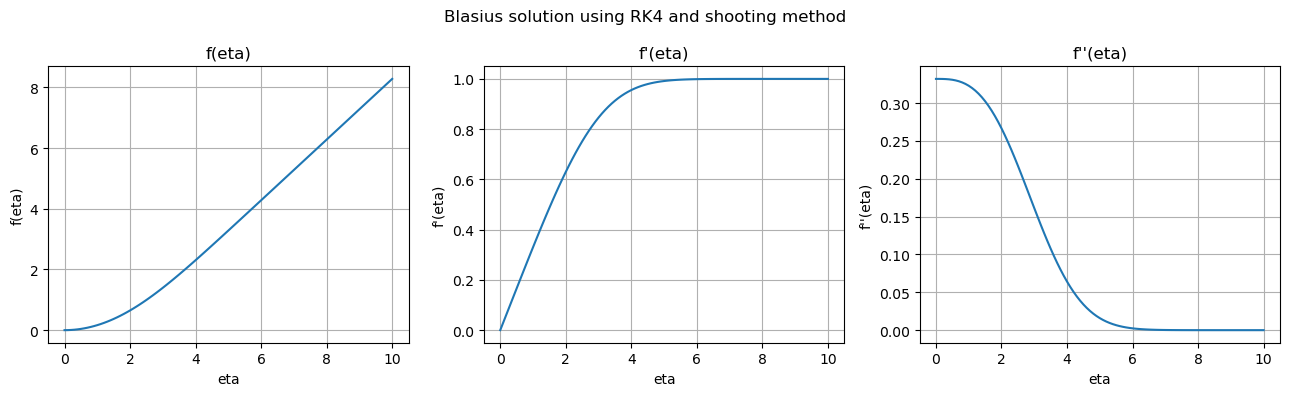

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].plot(eta_RK4, Y_RK4[:, 0])
ax[0].set_xlabel("eta")
ax[0].set_ylabel("f(eta)")
ax[0].set_title("f(eta)")

ax[1].plot(eta_RK4, Y_RK4[:, 1])
ax[1].set_xlabel("eta")
ax[1].set_ylabel("f'(eta)")
ax[1].set_title("f'(eta)")

ax[2].plot(eta_RK4, Y_RK4[:, 2])
ax[2].set_xlabel("eta")
ax[2].set_ylabel("f''(eta)")
ax[2].set_title("f''(eta)")

for a in ax:
    a.grid(True)

plt.suptitle("Blasius solution using RK4 and shooting method")
plt.tight_layout()
plt.show()


## 11. RK4 step-size study

I repeat the shooting calculation with the same five step sizes used for RK3. For each value of $h$, I calculate the shooting parameter and its absolute error relative to $s_{\mathrm{ref}}=0.3320573362$.

I calculate the observed order using

$$
p=\frac{\log(E_i/E_{i+1})}{\log(h_i/h_{i+1})}.
$$

The classical RK4 method has a theoretical global order of four. The printed order values and the log–log plot show how closely the numerical results follow this expected behaviour.

In [10]:
s_RK4_values = []
error_RK4_values = []

for hi in h_values:
    si = bisection_RK4(0.2, 0.5, eps, hi)
    s_RK4_values.append(si)
    error_RK4_values.append(abs(si - s_reference))

print("RK4 convergence results")
print("h           shooting parameter       absolute error")
for hi, si, ei in zip(h_values, s_RK4_values, error_RK4_values):
    print(f"{hi:<10} {si:.12f}          {ei:.6e}")

order_RK4 = []
for i in range(len(h_values) - 1):
    p = np.log(error_RK4_values[i] / error_RK4_values[i+1]) / np.log(h_values[i] / h_values[i+1])
    order_RK4.append(p)

print("Observed RK4 orders:", order_RK4)


RK4 convergence results
h           shooting parameter       absolute error
0.4        0.332058815839          1.479639e-06
0.2        0.332057457451          1.212506e-07
0.1        0.332057345611          9.410542e-09
0.05       0.332057337757          1.557283e-09
0.025      0.332057337239          1.039144e-09
Observed RK4 orders: [np.float64(3.6091819746603377), np.float64(3.6875697552446627), np.float64(2.595246985842184), np.float64(0.5836357405227245)]


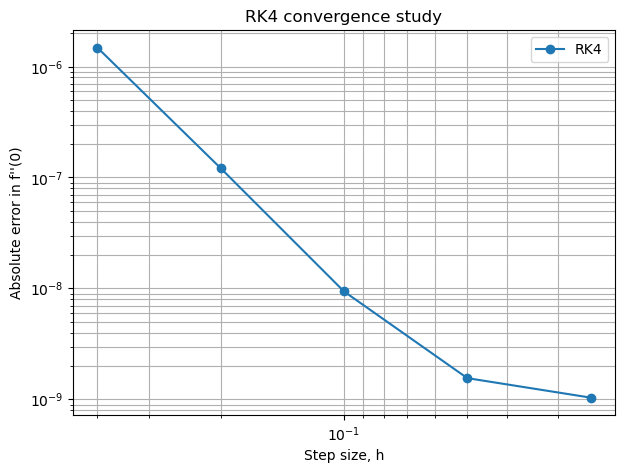

In [11]:
plt.figure(figsize=(7, 5))
plt.loglog(h_values, error_RK4_values, "o-", label="RK4")
plt.xlabel("Step size, h")
plt.ylabel("Absolute error in f''(0)")
plt.title("RK4 convergence study")
plt.grid(True, which="both")
plt.legend()
plt.gca().invert_xaxis()
plt.show()


### Comment on the RK4 results

The RK4 error values and the log–log plot show how the solution changes as the step size is reduced. The theoretical order is four. I compare the calculated orders with this value, keeping in mind that the coarser step sizes may not yet show the asymptotic behaviour clearly. The actual values printed by the notebook should be quoted in the final discussion.

## 12. Comparison of RK3 and RK4

Both methods solve the same first-order system and use the same shooting condition. The difference is in the number of stages used during each integration step:

- RK3 uses three stages and has a theoretical global error of order $O(h^3)$.
- RK4 uses four stages and has a theoretical global error of order $O(h^4)$.

I compare the shooting parameters, error values, and convergence plots from the two methods. RK4 is expected to give a more accurate result for sufficiently small step sizes, although it requires one additional function evaluation per step.

## 13. Conclusion

In this assignment, I solved the Blasius boundary-value problem by using the shooting method. I first converted the third-order equation into three first-order equations. Since the wall value $f''(0)$ was not given, I treated it as an unknown parameter and used bisection to adjust it until the far-field velocity condition was satisfied.

I carried out the integration using both RK3 and RK4. The solution profiles were plotted, and the shooting calculation was repeated for the five step sizes specified in the assignment. The accepted value of the wall parameter is approximately

$$
\boxed{f''(0)\approx0.332057.}
$$

The velocity profile should start from zero at the wall and approach one away from the plate. The value of $f''(\eta)$ should decrease towards zero. Finally, the convergence studies allow me to check the expected third-order behaviour of RK3 and fourth-order behaviour of RK4.

This exercise helped me understand how a boundary-value problem can be converted into an initial-value problem and solved by combining numerical integration with a root-finding method.